In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones planificadas (semanas) y presupuesto por actividad (BAC, en k€) se adjunta. El coste planificado de cada actividad se reparte uniformemente a lo largo de su duración.

In [4]:
#| tbl-cap: "Planificación del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC
    ('A'     , '---'      , 2       , 60 ),
    ('B'     , '---'      , 7       , 50 ),
    ('C'     , 'A,B'      , 1       , 30 ),
    ('D'     , 'A'        , 6       , 30 ),
    ('E'     , 'A'        , 1       , 20 ),
    ('F'     , 'C,E'      , 7       , 40 ),
    ('G'     , 'C,D,E'    , 2       , 20 ),
    ('H'     , 'F,G'      , 1       , 40 ),
], columns=['activity', 'predecessor', 'duration', 'BAC']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC
activity,,,
A,---,2,60
B,---,7,50
C,"A,B",1,30
D,A,6,30
E,A,1,20
F,"C,E",7,40
G,"C,D,E",2,20
H,"F,G",1,40


El proyecto corresponde a la rehabilitación de una nave industrial para un taller; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Levantamiento topográfico y mediciones',
    'B': 'Proyecto de ejecución y licencia',
    'C': 'Desmontaje de instalaciones antiguas',
    'D': 'Demolición de tabiquería interior',
    'E': 'Refuerzo de la estructura metálica',
    'F': 'Reparación de la cubierta',
    'G': 'Solera y canalizaciones',
    'H': 'Cerramientos y carpintería exterior',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Levantamiento topográfico y mediciones
B,Proyecto de ejecución y licencia
C,Desmontaje de instalaciones antiguas
D,Demolición de tabiquería interior
E,Refuerzo de la estructura metálica
F,Reparación de la cubierta
G,Solera y canalizaciones
H,Cerramientos y carpintería exterior


Se han realizado tres puntos de control, al final de las semanas 5, 9 y 13. En cada uno se anotó, para cada actividad, las semanas trabajadas hasta ese momento, el coste real incurrido (k€) y el porcentaje realizado.

In [6]:
#| tbl-cap: "Punto de control 1 (final de la semana 5)"
#| label: tbl-seguimiento1
seguimiento_1 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 78, 100      ),
    ('B'     , 5              , 30, 50       ),
    ('C'     , 0              , 0 , 0        ),
    ('D'     , 1              , 4 , 17       ),
    ('E'     , 1              , 26, 100      ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_1

,actual_duration,AC,performed
activity,,,
A,4,78,100
B,5,30,50
C,0,0,0
D,1,4,17
E,1,26,100
F,0,0,0
G,0,0,0
H,0,0,0


In [7]:
#| tbl-cap: "Punto de control 2 (final de la semana 9)"
#| label: tbl-seguimiento2
seguimiento_2 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 78, 100      ),
    ('B'     , 9              , 54, 90       ),
    ('C'     , 0              , 0 , 0        ),
    ('D'     , 5              , 22, 83       ),
    ('E'     , 1              , 26, 100      ),
    ('F'     , 0              , 0 , 0        ),
    ('G'     , 0              , 0 , 0        ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_2

,actual_duration,AC,performed
activity,,,
A,4,78,100
B,9,54,90
C,0,0,0
D,5,22,83
E,1,26,100
F,0,0,0
G,0,0,0
H,0,0,0


In [8]:
#| tbl-cap: "Punto de control 3 (final de la semana 13)"
#| label: tbl-seguimiento3
seguimiento_3 = pd.DataFrame([
#  activity, actual_duration, AC, performed
    ('A'     , 4              , 78, 100      ),
    ('B'     , 10             , 60, 100      ),
    ('C'     , 1              , 36, 100      ),
    ('D'     , 6              , 27, 100      ),
    ('E'     , 1              , 26, 100      ),
    ('F'     , 2              , 8 , 22       ),
    ('G'     , 2              , 15, 50       ),
    ('H'     , 0              , 0 , 0        ),
], columns=['activity', 'actual_duration', 'AC', 'performed']).set_index('activity')
seguimiento_3

,actual_duration,AC,performed
activity,,,
A,4,78,100
B,10,60,100
C,1,36,100
D,6,27,100
E,1,26,100
F,2,8,22
G,2,15,50
H,0,0,0


In [9]:
pregunta_1 = "1. Calcule PV, EV y AC en cada punto de control.  "
pregunta_2 = "2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  "
pregunta_3 = "3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  "
pregunta_4 = "4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule PV, EV y AC en cada punto de control.  

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

# Resolución

In [10]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
BAC_total = float(datos_proyecto['BAC'].sum())
duracion_planificada = proyecto.duration(datos_proyecto['duration'])

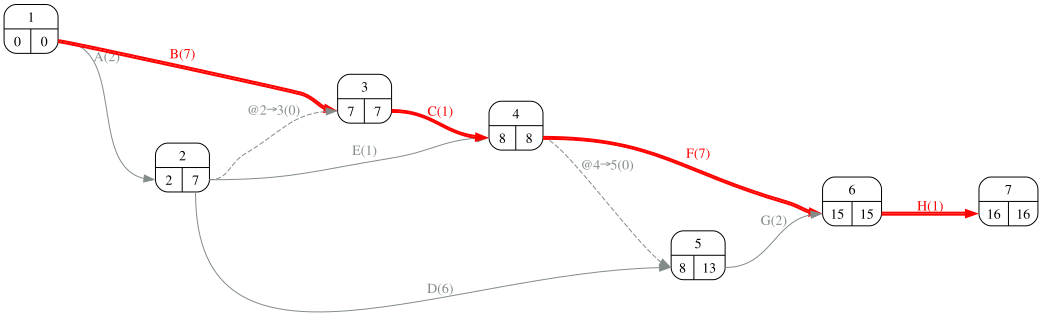

In [11]:
#| fig-cap: "Grafo PERT de la planificación"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

## Apartado 1

In [12]:
display(Markdown(pregunta_1))

1. Calcule PV, EV y AC en cada punto de control.  

In [13]:
seguimientos = {5: seguimiento_1, 9: seguimiento_2, 13: seguimiento_3}
filas = {}
curvas = {}
for semana, seguimiento in seguimientos.items():
    datos_vg = pd.concat([datos_proyecto, seguimiento], axis=1)
    gantts = EarnedValue(proyecto.copy()).calcula_gantts(datos_vg, planned_durations_label='duration',
                                                          actual_durations_label='actual_duration', PV_label='BAC',
                                                          AC_label='AC', percentage_complete_label='performed', tikz=False)
    PV = float(gantts['acumulados'].loc[semana, 'PV'])
    EV = float((datos_vg['BAC'] * datos_vg['performed'] / 100).sum())
    AC = float(datos_vg['AC'].sum())
    filas[semana] = {'PV': PV, 'EV': EV, 'AC': AC}
indicadores = pd.DataFrame(filas).T
indicadores.index.name = 'semana'
indicadores.round(1)

,PV,EV,AC
semana,,,
5,130.7,110.1,138.0
9,205.7,149.9,180.0
13,238.6,208.8,250.0


## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Calcule CV, SV, CPI y SPI en cada punto de control y represente su evolución.  

In [15]:
indicadores['CV'] = indicadores['EV'] - indicadores['AC']
indicadores['SV'] = indicadores['EV'] - indicadores['PV']
indicadores['CPI'] = indicadores['EV'] / indicadores['AC']
indicadores['SPI'] = indicadores['EV'] / indicadores['PV']
indicadores.round(3)

,PV,EV,AC,CV,SV,CPI,SPI
semana,,,,,,,
5,130.714,110.1,138.0,-27.9,-20.614,0.798,0.842
9,205.714,149.9,180.0,-30.1,-55.814,0.833,0.729
13,238.571,208.8,250.0,-41.2,-29.771,0.835,0.875


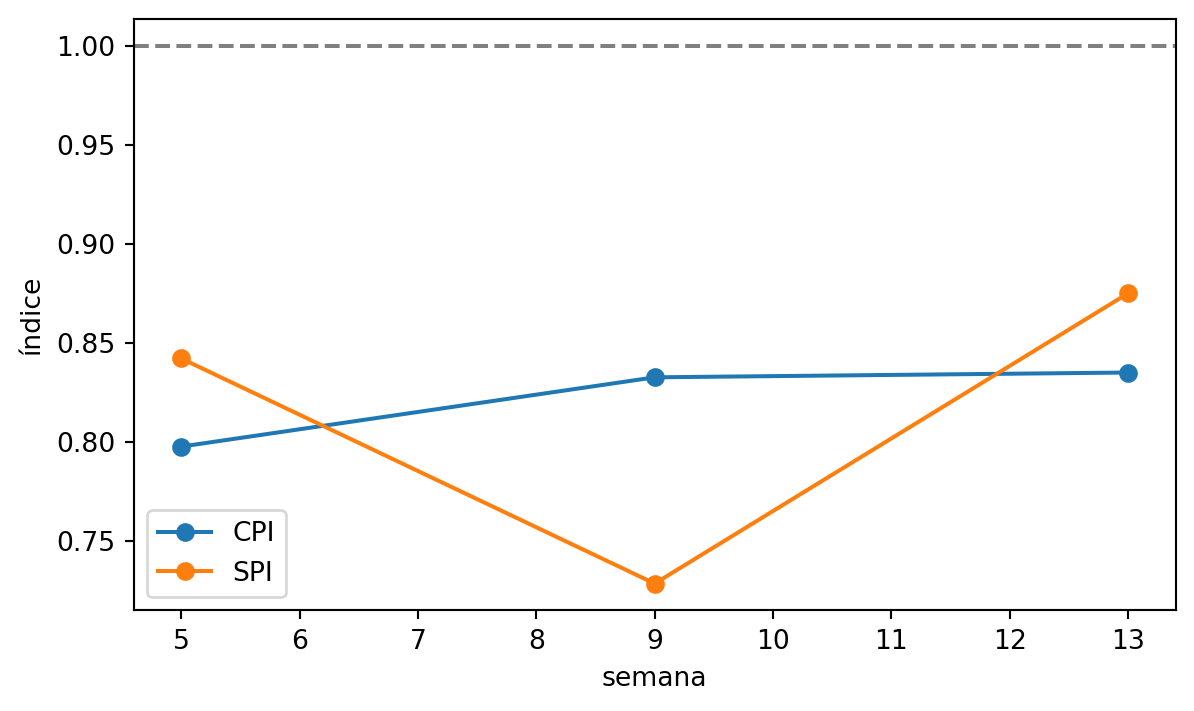

In [16]:
#| fig-cap: "Evolución de CPI y SPI"
#| label: fig-evolucion
ax = indicadores[['CPI', 'SPI']].plot(marker='o', figsize=(7, 4))
ax.axhline(1, color='grey', linestyle='--'); ax.set_ylabel('índice');

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. Calcule en cada punto la estimación del coste final EAC = BAC / CPI y comente la tendencia.  

In [18]:
indicadores['EAC'] = BAC_total / indicadores['CPI']
indicadores['VAC'] = BAC_total - indicadores['EAC']
indicadores[['CPI', 'EAC', 'VAC']].round({'CPI': 3, 'EAC': 1, 'VAC': 1})

,CPI,EAC,VAC
semana,,,
5,0.798,363.5,-73.5
9,0.833,348.2,-58.2
13,0.835,347.2,-57.2


## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. A la vista de la evolución, ¿el proyecto se está recuperando o deteriorando? ¿Qué decisiones tomaría tras el último punto de control?  

In [20]:
cpi = indicadores['CPI']; spi = indicadores['SPI']
tend_c = 'mejora' if cpi.iloc[-1] > cpi.iloc[0] else 'empeora'
tend_s = 'mejora' if spi.iloc[-1] > spi.iloc[0] else 'empeora'
Markdown(f'''Entre el primer y el último punto de control el CPI {tend_c} ({cpi.iloc[0]:.2f} → {cpi.iloc[-1]:.2f}) y el SPI {tend_s} ({spi.iloc[0]:.2f} → {spi.iloc[-1]:.2f}). La previsión de coste final pasa de {indicadores["EAC"].iloc[0]:.0f} a {indicadores["EAC"].iloc[-1]:.0f} k€ frente a un presupuesto de {BAC_total:.0f}. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.''')

Entre el primer y el último punto de control el CPI mejora (0.80 → 0.84) y el SPI mejora (0.84 → 0.88). La previsión de coste final pasa de 363 a 347 k€ frente a un presupuesto de 290. Conviene recordar que el SPI tiende a 1 al final del proyecto aunque haya retraso, así que su mejora en los últimos puntos puede ser aparente; para el plazo es preferible la programación ganada. Tras el último control procede revisar las actividades pendientes: acelerar las críticas (si el sobrecoste compensa la penalización o los costes indirectos) y revisar las causas del sobrecoste en las ya ejecutadas para que no se repitan.